# 06 ARIMA und SARIMAX auf dem Tagesrücklauf

Teil 2: Begehungen und Wirkung

**Worum es geht**
- Taugen ARIMA oder SARIMAX als Prognose für das Tagesmittel des Rücklaufs? ARIMA = Modell, das eine Reihe aus ihren eigenen letzten Werten fortschreibt. SARIMAX = dasselbe mit Saisonterm und äußeren Größen, hier die Außentemperatur
- Ziel: die Wirkung einer Begehung messen, ohne dass die Jahreszeit sie überdeckt (Problem aus Notebook 02 und 15)
- Ablauf: Modellvergleich ohne Begehung, dann Prognose der Zeit nach der Begehung aus dem Vorher-Modell, dazu Placebo und Kontrollgruppe
- Eine Abweichung ist ein Hinweis, kein Nachweis

**Daten**
- liest: Stundenreihen aus Notebook 00 über `src/nb00_daten.py`, Außentemperatur DWD Kitzingen (wie Notebook 04) über `src/weather.py`, Begehungen über `src/load_begehungen.py`, `data/processed/begehungs_wirkung.csv`
- schreibt: `data/processed/arima_begehungen.csv`, `data/processed/arima_modellvergleich.csv` (gitignored)
- vorher ausführen: Notebook 00, 02

**Code**
- Logik in `src/zeitreihenmodell.py`, Tests in `tests/test_zeitreihenmodell.py`
- Regression mit AR-Fehlern (SARIMAX ohne MA-Teil), weil statsmodels fehlt

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import load_begehungen as lb
from src import nb00_daten as nb00
from src import weather
from src import zeitreihenmodell as zm

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (9, 4)

## 1 Daten und Tagesreihe

- Stundenreihen aus Notebook 00
- Tageswert = Mittel des Rücklaufs über die Stunden mit mehr als 0,5 kW Leistung, mindestens 12 solche Stunden je Tag
- Tage ab 15 °C Außentemperatur und Lücken bleiben leer

In [2]:
serien = nb00.lade_serien()
ladefehler = nb00.nicht_aufbereitet()
hist_von = min(d.index[0] for d in serien.values() if len(d)).normalize()
hist_bis = max(d.index[-1] for d in serien.values() if len(d)).normalize()
t_out = weather.load_outdoor_temperature(hist_von, hist_bis + pd.Timedelta(days=1),
                                         allow_download=False)

tage = {z: zm.tagesreihe(d, t_out) for z, d in serien.items() if len(d)}
heiztage = pd.Series({z: int(t["y"].notna().sum()) for z, t in tage.items()})
print(f"{len(serien)} Zählerreihen geladen, {len(ladefehler)} nicht ladbar")
print(f"Historie {hist_von.date()} .. {hist_bis.date()} ({(hist_bis - hist_von).days} Tage)")
print(f"Außentemperatur: {len(t_out)} Stunden, "
      f"{int(t_out['interpolated'].sum())} interpoliert")
print()
print("gültige Heiztage je Zähler (Tagesmittel Rücklauf mit Last, Außentemperatur unter 15 °C):")
display(heiztage.describe().round(0))
print(f"Zähler mit weniger als 120 gültigen Heiztagen: {(heiztage < 120).sum()}")
print(f"Zähler mit weniger als 40: {(heiztage < 40).sum()}")

93 Zählerreihen geladen, 9 nicht ladbar
Historie 2021-11-01 .. 2026-07-20 (1722 Tage)
Außentemperatur: 41348 Stunden, 7 interpoliert

gültige Heiztage je Zähler (Tagesmittel Rücklauf mit Last, Außentemperatur unter 15 °C):


count     93.0
mean     365.0
std      138.0
min        2.0
25%      292.0
50%      386.0
75%      444.0
max      647.0
dtype: float64

Zähler mit weniger als 120 gültigen Heiztagen: 5
Zähler mit weniger als 40: 3


- 93 Zählerreihen, Historie 01.11.2021 bis 20.07.2026
- Gültige Heiztage je Zähler im Median 386. 5 Zähler haben weniger als 120, 3 weniger als 40
- In die Modellvergleiche gehen nur Zähler mit mindestens 120 gültigen Heiztagen

## 2 Die verglichenen Modelle

- Alle Modelle sind Spezialfälle von `u = y - X*beta`, `phi(L) * Phi(L^7) * (1-L)^d * u = Fehler` (y = Rücklauf, X = äußere Größen, L = Verschiebung um einen Tag)
- Ohne äußere Größe und mit d = 1 ist das ARIMA. Mit Außentemperatur und Wochenterm (Periode 7 Tage) ist es SARIMAX
- `kennlinie`: reine Regression Rücklauf gegen Außentemperatur. Zeigt, was die AR-Terme (Abhängigkeit von den Vortagen) zusätzlich bringen
- `naiv_7`: Mittel der letzten 7 Tage, als einfacher Vergleich

In [3]:
modelle = zm.standard_modelle()
beschr = pd.DataFrame([{
    "modell": s.name,
    "AR p": s.p,
    "saisonal P (7 Tage)": s.P,
    "Differenz d": s.d,
    "exogen": ", ".join(s.exog) or "-",
    "Konstante": s.konstante and s.d == 0,
} for s in modelle])
beschr.loc[len(beschr)] = ["naiv_7", 0, 0, 0, "-", "Mittel der letzten 7 Tage"]
display(beschr)

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37257/1427118160.py:10: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype bool cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  beschr.loc[len(beschr)] = ["naiv_7", 0, 0, 0, "-", "Mittel der letzten 7 Tage"]


,modell,AR p,saisonal P (7 Tage),Differenz d,exogen,Konstante
0,arima_110,1,0,1,-,False
1,arma_200,2,0,0,-,True
2,kennlinie,0,0,0,t_out,True
3,arx_100,1,0,0,t_out,True
4,sarimax_100_100,1,1,0,t_out,True
5,sarimax_lag,1,1,0,"t_out, t_out_l1",True
6,naiv_7,0,0,0,-,Mittel der letzten 7 Tage


## 3 Prognosefehler ohne Begehung

- Je Zähler rollende Fenster: 56 Tage anpassen, 14 Tage vorhersagen, Außentemperatur als bekannt angenommen
- Fenster mit Begehung bleiben draußen. Gewertet werden nur Fenster, in denen alle Modelle eine Prognose haben
- Danach Paarvergleich je Zähler mit dem Wilcoxon-Test (Rangtest für gepaarte Werte), weil die Fenster eines Zählers nicht unabhängig sind

In [4]:
begehungen_je_meter = lb.begehung_dates_by_meter(available=set(serien))

teile = []
for z, t in tage.items():
    if t["y"].notna().sum() < 120:
        continue
    r = zm.rollender_vergleich(t, modelle, train_tage=56, horizont=14, schritt=14,
                               sperrdaten=begehungen_je_meter.get(z, []))
    if len(r):
        r["meter"] = z
        teile.append(r)
kurz = pd.concat(teile, ignore_index=True)

voll = kurz.groupby(["meter", "ursprung"])["modell"].transform("nunique") == kurz["modell"].nunique()
kurz = kurz[voll]
w = kurz.pivot_table(index=["meter", "ursprung"], columns="modell", values="mae")
print(f"{w.index.get_level_values('meter').nunique()} Zähler, {len(w)} Prognosefenster à 14 Tage")

tab = kurz.groupby("modell")[["mae", "rmse", "bias"]].mean().round(2)
tab["mae_median"] = kurz.groupby("modell")["mae"].median().round(2)
tab["besser_als_naiv"] = [round(float((w[m] < w["naiv_7"]).mean()), 2) for m in tab.index]
tab = tab.sort_values("mae")
display(tab)

/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


87 Zähler, 1695 Prognosefenster à 14 Tage


,mae,rmse,bias,mae_median,besser_als_naiv
modell,,,,,
arx_100,2.11,2.54,0.19,1.64,0.66
sarimax_100_100,2.20,2.64,0.06,1.65,0.64
sarimax_lag,2.21,2.66,0.07,1.66,0.63
kennlinie,2.26,2.68,0.21,1.69,0.63
naiv_7,2.66,3.15,0.03,2.02,0.00
arma_200,2.68,3.16,-0.03,2.04,0.48
arima_110,2.79,3.31,-0.04,2.17,0.43


In [5]:
wm = w.groupby("meter").mean()
paare = [("arx_100", "naiv_7"), ("arx_100", "arima_110"), ("arx_100", "kennlinie"),
         ("sarimax_100_100", "arx_100"), ("sarimax_lag", "sarimax_100_100"),
         ("arima_110", "naiv_7"), ("arma_200", "naiv_7")]
zeilen = []
for a, b in paare:
    diff = wm[a] - wm[b]
    zeilen.append({
        "A": a, "B": b,
        "Median MAE A - B (°C)": round(float(diff.median()), 3),
        "Zähler mit A besser": f"{int((diff < 0).sum())} von {len(diff)}",
        "Wilcoxon p": float(f"{stats.wilcoxon(wm[a], wm[b]).pvalue:.2g}"),
    })
display(pd.DataFrame(zeilen))
print()
print("bestes Modell je Zähler (kleinster mittlerer MAE):")
display(wm.idxmin(axis=1).value_counts())

,A,B,Median MAE A - B (°C),Zähler mit A besser,Wilcoxon p
0,arx_100,naiv_7,-0.328,71 von 87,6.600000e-11
1,arx_100,arima_110,-0.458,79 von 87,2.100000e-14
2,arx_100,kennlinie,-0.016,56 von 87,3.700000e-04
3,sarimax_100_100,arx_100,0.025,29 von 87,8.900000e-04
4,sarimax_lag,sarimax_100_100,0.024,31 von 87,2.900000e-02
5,arima_110,naiv_7,0.197,20 von 87,8.500000e-06
6,arma_200,naiv_7,0.035,41 von 87,3.900000e-01



bestes Modell je Zähler (kleinster mittlerer MAE):


arx_100            26
kennlinie          15
sarimax_lag        15
naiv_7             10
sarimax_100_100    10
arma_200            7
arima_110           4
Name: count, dtype: int64

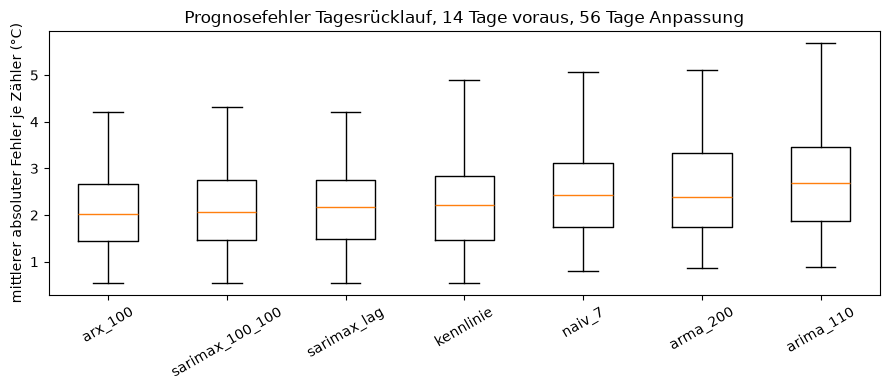

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
reihenfolge = tab.index.tolist()
ax.boxplot([wm[m].dropna() for m in reihenfolge], showfliers=False)
ax.set_xticklabels(reihenfolge)
ax.set_ylabel("mittlerer absoluter Fehler je Zähler (°C)")
ax.set_title("Prognosefehler Tagesrücklauf, 14 Tage voraus, 56 Tage Anpassung")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

- 87 Zähler, 1.695 Fenster. `arx_100` (Außentemperatur plus AR(1)) ist am besten: mittlerer Fehler 2,11 °C gegen 2,66 °C naiv. Je Zähler im Median 0,33 °C besser als das 7-Tage-Mittel und 0,46 °C besser als ARIMA(1,1,0)
- Reines ARIMA ist schlechter als naiv. Ohne Wetter schreibt es nur den letzten Stand fort
- Der Wochenterm bringt nichts, der AR-Term gegenüber der reinen Kennlinie nur 0,02 °C. Der Gewinn kommt aus der Außentemperatur

## 4 Prognosefenster für die Begehungen

- Anpassung auf bis zu 365 Tagen vor dem Termin (nur Heiztage), Prognose der folgenden 90 Tage
- Das Vorjahr wird so über die Außentemperatur verglichen statt über den Kalender
- Gleich lange Fenster ohne Begehung liefern das normale Prognoserauschen

In [7]:
exogene = [s for s in modelle if s.exog]
teile = []
for z, t in tage.items():
    if t["y"].notna().sum() < 120:
        continue
    r = zm.rollender_vergleich(t, exogene, train_tage=365, horizont=90, schritt=30,
                               min_train_gueltig=40, min_test_gueltig=10,
                               sperrdaten=begehungen_je_meter.get(z, []))
    if len(r):
        r["meter"] = z
        teile.append(r)
lang = pd.concat(teile, ignore_index=True)
voll = lang.groupby(["meter", "ursprung"])["modell"].transform("nunique") == lang["modell"].nunique()
lang = lang[voll]

def robust_sd(s):
    return 1.4826 * np.median(np.abs(s - np.median(s)))


sd_lang = lang.groupby("modell")["bias"].agg(robust_sd)
tl = lang.groupby("modell")[["mae", "rmse", "bias"]].mean().round(2)
tl["mae_median"] = lang.groupby("modell")["mae"].median().round(2)
tl["sd_bias_robust"] = sd_lang.round(2)
print(f"{lang['meter'].nunique()} Zähler, {lang.groupby(['meter','ursprung']).ngroups} Fenster "
      f"(365 Tage Anpassung, 90 Tage Prognose, ohne Begehung im Fenster)")
display(tl.sort_values("mae"))

60 Zähler, 710 Fenster (365 Tage Anpassung, 90 Tage Prognose, ohne Begehung im Fenster)


,mae,rmse,bias,mae_median,sd_bias_robust
modell,,,,,
arx_100,3.30,3.92,-0.48,2.28,1.65
kennlinie,3.36,3.96,-0.58,2.34,1.62
sarimax_100_100,3.40,4.03,-0.52,2.31,1.80
sarimax_lag,3.40,4.02,-0.58,2.27,1.74
naiv_7,3.77,4.50,-0.45,2.73,2.28


- Ohne Begehung ist `arx_100` wieder am besten (mittlerer Fehler 3,30 °C, robuste Streuung 1,65 °C; 60 Zähler, 710 Fenster)
- Abweichung = Messung minus Prognose, gemittelt über die Heiztage nach der Begehung. Negativ heißt: Rücklauf niedriger als bei gleichem Wetter erwartet
- `z` = Abweichung geteilt durch die robuste Streuung ohne Begehung (MAD mal 1,4826; MAD = Median der absoluten Abweichungen vom Median)

In [8]:
MODELL = "arx_100"
spec = {s.name: s for s in modelle}
sd = float(sd_lang[MODELL])

beg = lb.begehungen_mit_zaehler(available=set(serien)).dropna(subset=["meter", "datum"])
beg["meter"] = beg["meter"].astype(int)
zeilen = []
for _, r in beg.iterrows():
    t = tage.get(r["meter"])
    if t is None:
        continue
    zeile = {"meter": r["meter"], "datum": r["datum"].normalize(), "kategorie": r["kategorie"],
             "zaehlerwechsel": bool(r.get("meter_gewechselt", False))}
    for name in ("kennlinie", "arx_100", "sarimax_100_100"):
        wk = zm.wirkung_begehung(t, r["datum"], spec[name])
        zeile[name] = np.nan if wk is None else wk["abw"]
        if name == MODELL and wk is not None:
            zeile["n_post"] = wk["n_post"]
            zeile["rt_vor"] = wk["rt_vor"]
            zeile["rt_nach"] = wk["rt_nach"]
    zeilen.append(zeile)
ergebnis = pd.DataFrame(zeilen)
ergebnis["z"] = ergebnis[MODELL] / sd
ok = ergebnis.dropna(subset=[MODELL]).copy()

print(f"{len(ergebnis)} Begehungen mit Zähler und Datum, {len(ok)} auswertbar "
      f"({len(ergebnis) - len(ok)} ohne genug Heiztage davor oder danach)")
print(f"Begehungsdatum der auswertbaren: {ok['datum'].min().date()} .. {ok['datum'].max().date()}")
print()
display(ok.sort_values("z")[["meter", "datum", "kategorie", "zaehlerwechsel", "kennlinie",
                              "arx_100", "sarimax_100_100", "n_post", "z"]].round(2)
        .reset_index(drop=True))

/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


53 Begehungen mit Zähler und Datum, 40 auswertbar (13 ohne genug Heiztage davor oder danach)
Begehungsdatum der auswertbaren: 2024-08-26 .. 2025-09-16



/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37257/2892272621.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "arx_100", "sarimax_100_100", "n_post", "z"]].round(2)


,meter,datum,kategorie,zaehlerwechsel,kennlinie,arx_100,sarimax_100_100,n_post,z
0,68956351,2024-09-09,viele,False,-32.59,-32.52,-32.46,46.0,-19.74
1,68956372,2024-10-14,viele,False,-14.91,-15.65,NaN,90.0,-9.50
2,68956355,2024-09-16,viele,False,-10.95,-10.88,-10.50,77.0,-6.60
3,69527345,2024-09-17,viele,False,-11.51,-9.59,-6.10,75.0,-5.82
4,80912190,2024-09-12,mittlere,False,-9.69,-8.93,-7.54,73.0,-5.42
5,68956345,2024-09-18,mittlere,False,-8.83,-8.85,-8.99,77.0,-5.37
6,80912197,2024-09-20,geringe,False,-7.39,-7.05,-7.34,73.0,-4.28
7,68956359,2024-09-26,mittlere,False,-4.28,-4.30,-4.58,39.0,-2.61
8,68956373,2025-03-12,mittlere,False,-4.33,-4.19,-4.41,24.0,-2.54
9,80912193,2024-11-05,mittlere,False,-4.64,-3.69,-4.20,90.0,-2.24


In [9]:
print("Kategorie der Begehung gegen Abweichung (arx_100, °C; negativ = Rücklauf niedriger als erwartet):")
display(ok.groupby("kategorie")[MODELL].agg(["count", "median", "mean"]).round(2))
print()
#stimmen die drei Modelle mit Außentemperatur auf den Begehungen überein?
exo = ok[["kennlinie", "arx_100", "sarimax_100_100"]].dropna()
print("Rangkorrelation der Abweichungen zwischen den Modellen (n = %d):" % len(exo))
display(exo.corr(method="spearman").round(3))
print()
#Abgleich mit Vorher/Nachher aus Notebook 02
alt = pd.read_csv("../data/processed/begehungs_wirkung.csv", parse_dates=["datum"])
vgl = ok.merge(alt[["meter", "datum", "d_rt", "did"]], on=["meter", "datum"], how="inner")
print(f"Abgleich mit Notebook 03 (Rücklaufänderung nachher minus vorher): {len(vgl)} gemeinsame Begehungen")
for spalte in ("d_rt", "did"):
    v = vgl.dropna(subset=[spalte])
    rho, p = stats.spearmanr(v[MODELL], v[spalte])
    print(f"  Spearman Modellabweichung gegen {spalte}: rho = {rho:.2f}, p = {p:.3g}, n = {len(v)}")

Kategorie der Begehung gegen Abweichung (arx_100, °C; negativ = Rücklauf niedriger als erwartet):


,count,median,mean
kategorie,,,
geringe,3,7.33,2.89
keine,2,-1.77,-1.77
mittlere,25,-1.46,-0.79
viele,10,-0.32,-6.37



Rangkorrelation der Abweichungen zwischen den Modellen (n = 39):


,kennlinie,arx_100,sarimax_100_100
kennlinie,1.000,0.987,0.945
arx_100,0.987,1.000,0.955
sarimax_100_100,0.945,0.955,1.000



Abgleich mit Notebook 03 (Rücklaufänderung nachher minus vorher): 39 gemeinsame Begehungen
  Spearman Modellabweichung gegen d_rt: rho = 0.54, p = 0.000343, n = 39
  Spearman Modellabweichung gegen did: rho = 0.54, p = 0.000334, n = 39


- 40 von 53 Begehungen auswertbar, 13 ohne genug Heiztage davor oder danach. Termine vom 26.08.2024 bis 16.09.2025
- Die drei Modelle mit Außentemperatur sind sich einig (Rangkorrelation mindestens 0,95 bei 39 Begehungen)
- Zusammenhang mit der Rücklaufänderung aus Notebook 02 (Spearman 0,54, n = 39), aber kein unabhängiger Beleg

## 5 Placebo und Kontrollgruppe

- Placebo: wie oft liegt ein Fenster ohne Begehung außerhalb von z = ±2?
- Kontrollgruppe: Stationen ohne Begehung bekommen ein Pseudodatum aus den echten Terminen, bis zu 3 Ziehungen je Station
- So liegen beide Gruppen im selben Kalenderfenster

In [10]:
def anteile(z, schwelle=2.0):
    z = np.asarray(z, dtype=float)
    z = z[np.isfinite(z)]
    return int((np.abs(z) > schwelle).sum()), len(z)


p_alle = lang[lang["modell"] == MODELL].copy()
p_alle["z"] = p_alle["bias"] / sd
p_herbst = p_alle[p_alle["ursprung"].dt.month.isin([8, 9, 10, 11])]

n_b, m_b = anteile(ok["z"])
n_a, m_a = anteile(p_alle["z"])
n_h, m_h = anteile(p_herbst["z"])
print("Anteil Fenster mit |z| > 2:")
print(f"  Begehungen:                   {n_b} von {m_b} ({n_b / m_b:.0%})")
print(f"  Fenster ohne Begehung, alle:  {n_a} von {m_a} ({n_a / m_a:.0%})")
print(f"  Fenster ohne Begehung, Aug-Nov: {n_h} von {m_h} ({n_h / m_h:.0%})")
for name, (n, m) in {"alle": (n_a, m_a), "Aug-Nov": (n_h, m_h)}.items():
    p = stats.binomtest(n_b, m_b, n / m, alternative="greater").pvalue
    print(f"  Binomialtest Begehung gegen Placebo {name}: p = {p:.3g}")

neg = (ok["z"] < -2).sum()
pos = (ok["z"] > 2).sum()
print()
print(f"Begehungen mit z < -2 (Rücklauf deutlich niedriger): {neg}, mit z > 2 (höher): {pos}")
print(f"Placebo Aug-Nov: z < -2 in {(p_herbst['z'] < -2).mean():.1%}, z > 2 in {(p_herbst['z'] > 2).mean():.1%}")

Anteil Fenster mit |z| > 2:
  Begehungen:                   16 von 40 (40%)
  Fenster ohne Begehung, alle:  138 von 710 (19%)
  Fenster ohne Begehung, Aug-Nov: 48 von 251 (19%)
  Binomialtest Begehung gegen Placebo alle: p = 0.00216
  Binomialtest Begehung gegen Placebo Aug-Nov: p = 0.00181

Begehungen mit z < -2 (Rücklauf deutlich niedriger): 11, mit z > 2 (höher): 5
Placebo Aug-Nov: z < -2 in 15.5%, z > 2 in 3.6%


In [11]:
rng = np.random.default_rng(42)
echte_termine = ok["datum"].tolist()
mit_begehung = set(beg["meter"])
kontrolle = []
for z, t in tage.items():
    if z in mit_begehung or t["y"].notna().sum() < 120:
        continue
    for ziehung in range(3):
        datum = echte_termine[rng.integers(len(echte_termine))]
        wk = zm.wirkung_begehung(t, datum, spec[MODELL])
        if wk is not None:
            kontrolle.append({"meter": z, "datum": datum, "ziehung": ziehung, "abw": wk["abw"]})
kontrolle = pd.DataFrame(kontrolle)
kontrolle["z"] = kontrolle["abw"] / sd
print(f"Kontrolle: {kontrolle['meter'].nunique()} Stationen ohne Begehung, "
      f"{len(kontrolle)} Pseudotermine (je Station bis zu 3 Ziehungen)")

n_k, m_k = anteile(kontrolle["z"])
print(f"|z| > 2: Begehung {n_b} von {m_b} ({n_b / m_b:.0%}), Kontrolle {n_k} von {m_k} ({n_k / m_k:.0%})")
print(f"Median Abweichung: Begehung {ok[MODELL].median():+.2f} °C, Kontrolle {kontrolle['abw'].median():+.2f} °C")
auff = kontrolle.loc[kontrolle["z"].abs() > 2, "meter"].nunique()
print(f"Kontrollstationen mit mindestens einer Ziehung |z| > 2: {auff} von {kontrolle['meter'].nunique()}")
u = stats.mannwhitneyu(ok[MODELL], kontrolle["abw"])
print(f"Mann-Whitney Begehung gegen Kontrolle: p = {u.pvalue:.3g}")
fe = stats.fisher_exact([[n_b, m_b - n_b], [n_k, m_k - n_k]])
print(f"Fisher für Anteil |z| > 2: p = {fe[1]:.3g}")
print()
print("Kontrolle mit |z| > 2, je Station (Pseudodatum):")
display(kontrolle[kontrolle["z"].abs() > 2].round(2).sort_values("z").reset_index(drop=True))

Kontrolle: 36 Stationen ohne Begehung, 97 Pseudotermine (je Station bis zu 3 Ziehungen)
|z| > 2: Begehung 16 von 40 (40%), Kontrolle 21 von 97 (22%)
Median Abweichung: Begehung -0.55 °C, Kontrolle -0.24 °C
Kontrollstationen mit mindestens einer Ziehung |z| > 2: 8 von 36
Mann-Whitney Begehung gegen Kontrolle: p = 0.228
Fisher für Anteil |z| > 2: p = 0.035

Kontrolle mit |z| > 2, je Station (Pseudodatum):


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37257/740635965.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(kontrolle[kontrolle["z"].abs() > 2].round(2).sort_values("z").reset_index(drop=True))


,meter,datum,ziehung,abw,z
0,69513891,2024-09-18,2,-20.61,-12.51
1,72167777,2024-09-17,2,-14.32,-8.69
2,69513891,2024-11-08,0,-11.62,-7.05
3,80912158,2024-09-19,1,-10.84,-6.58
4,80912158,2024-10-10,2,-10.79,-6.55
5,69513891,2024-11-19,1,-9.69,-5.88
6,72167777,2024-11-05,0,-7.85,-4.76
7,72167782,2024-11-05,0,-7.24,-4.39
8,72167782,2024-09-17,1,-6.26,-3.80
9,72135480,2024-09-17,1,-6.17,-3.75


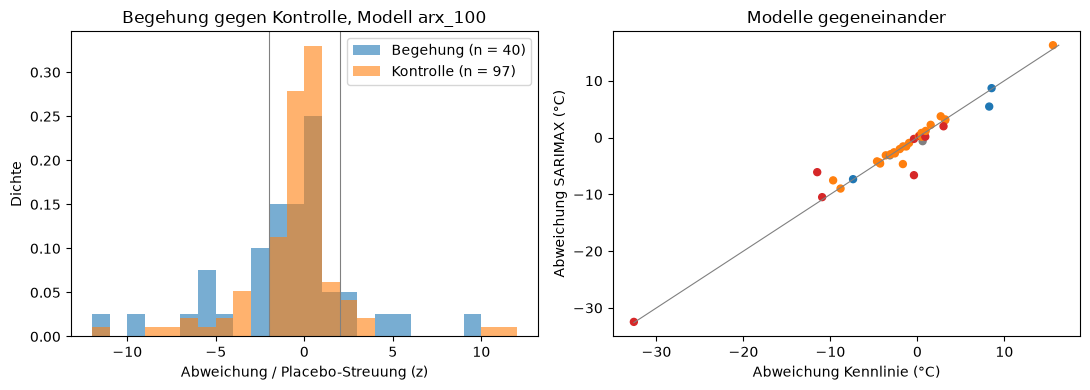

In [12]:
fig, achsen = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(-12, 12, 25)
achsen[0].hist(np.clip(ok["z"], -12, 12), bins=bins, alpha=0.6, density=True, label=f"Begehung (n = {len(ok)})")
achsen[0].hist(np.clip(kontrolle["z"], -12, 12), bins=bins, alpha=0.6, density=True, label=f"Kontrolle (n = {len(kontrolle)})")
achsen[0].axvline(-2, color="grey", lw=0.8)
achsen[0].axvline(2, color="grey", lw=0.8)
achsen[0].set_xlabel("Abweichung / Placebo-Streuung (z)")
achsen[0].set_ylabel("Dichte")
achsen[0].legend()
achsen[0].set_title("Begehung gegen Kontrolle, Modell arx_100")

o = ok.sort_values("z")
farben = o["kategorie"].map({"keine": "grey", "geringe": "tab:blue", "mittlere": "tab:orange", "viele": "tab:red"}).fillna("black")
achsen[1].scatter(o["kennlinie"], o["sarimax_100_100"], c=farben, s=25)
grenze = [min(o["kennlinie"].min(), o["sarimax_100_100"].min()), max(o["kennlinie"].max(), o["sarimax_100_100"].max())]
achsen[1].plot(grenze, grenze, color="grey", lw=0.8)
achsen[1].set_xlabel("Abweichung Kennlinie (°C)")
achsen[1].set_ylabel("Abweichung SARIMAX (°C)")
achsen[1].set_title("Modelle gegeneinander")
plt.tight_layout()

- Außerhalb von z = ±2: 16 von 40 Begehungen (40 %), 138 von 710 Placebo-Fenstern (19 %), 21 von 97 Kontrollterminen (22 %)
- Unterschied zum Placebo: Binomialtest p = 0,002. Zur Kontrolle: Fisher-Test p = 0,035
- 11 der 16 auffälligen Begehungen mit niedrigerem Rücklauf, 5 mit höherem
- Im typischen Fall kaum Unterschied: Median -0,55 °C gegen -0,24 °C bei der Kontrolle (Mann-Whitney p = 0,23)

## 6 Einzelfall Zähler 68956351

- Bekannter Befund: Ventil über drei Jahre offen, Reparatur am 09.09.2024
- Vorher-Modell auf den 365 Tagen davor angepasst, Prognose der 90 Tage danach

Koeffizienten: {'konstante': 67.77, 't_out': 0.44} phi: [0.7]
Rücklauf vor der Begehung (Heiztage, Mittel): 70.5 °C
Rücklauf danach: 37.7 °C, Prognose des Vorher-Modells: 71.9 °C


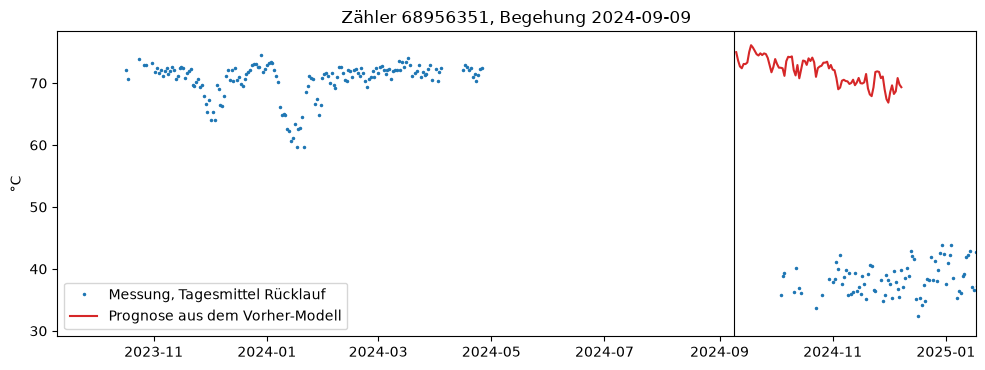

In [13]:
#steht nicht in der Begehungstabelle
fall = tage[68956351]
beginn = pd.Timestamp("2024-09-09")
train = fall.loc[beginn - pd.Timedelta(days=365):beginn - pd.Timedelta(days=1)]
post = fall.loc[beginn + pd.Timedelta(days=1):beginn + pd.Timedelta(days=90)]
anp = zm.fit(train, spec[MODELL])
pred = pd.Series(zm.prognose(anp, train, post), index=post.index)
print("Koeffizienten:", {k: round(float(v), 2) for k, v in zip(anp.spalten, anp.beta)}, "phi:", anp.phi.round(2))
print(f"Rücklauf vor der Begehung (Heiztage, Mittel): {train['y'].mean():.1f} °C")
print(f"Rücklauf danach: {post['y'].mean():.1f} °C, Prognose des Vorher-Modells: {pred.mean():.1f} °C")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(fall.index, fall["y"], ".", ms=3, color="tab:blue", label="Messung, Tagesmittel Rücklauf")
ax.plot(pred.index, pred, color="tab:red", label="Prognose aus dem Vorher-Modell")
ax.axvline(beginn, color="black", lw=0.8)
ax.set_xlim(beginn - pd.Timedelta(days=365), beginn + pd.Timedelta(days=130))
ax.set_ylabel("°C")
ax.legend()
ax.set_title("Zähler 68956351, Begehung 2024-09-09")
plt.tight_layout()

- Vorher 70,5 °C, danach 37,7 °C, Prognose des Vorher-Modells 71,9 °C
- Größte Abweichung unter allen ausgewerteten Begehungen (z = -19,7), gefunden ohne Labelwissen

## 7 Ergebnisse speichern

- `arima_begehungen.csv` (Abweichung je Begehung) und `arima_modellvergleich.csv` (Fehler je Modell) nach `data/processed/`

In [14]:
aus = Path("../data/processed")
ok.to_csv(aus / "arima_begehungen.csv", index=False)
kurz.groupby("modell")[["mae", "rmse", "bias"]].mean().to_csv(aus / "arima_modellvergleich.csv")
print("geschrieben: data/processed/arima_begehungen.csv, arima_modellvergleich.csv (gitignored)")

geschrieben: data/processed/arima_begehungen.csv, arima_modellvergleich.csv (gitignored)


## Zusammenfassung & Bewertung

**Ergebnis**
- Bestes Modell: Außentemperatur mit AR(1)-Fehlern (`arx_100`), mittlerer Fehler 2,11 °C gegen 2,66 °C naiv (87 Zähler, 1.695 Fenster)
- 16 von 40 Begehungen (40 %) liegen außerhalb von z = ±2, gegen 19 % der Placebo-Fenster (p = 0,002) und 22 % der Kontrolltermine (Fisher p = 0,035). 11 davon mit niedrigerem Rücklauf

**Belastbar**
- Die Außentemperatur lohnt sich als Erklärungsgröße
- Nach Begehungen gibt es häufiger einen deutlichen Sprung als bei Kontrollstationen
- Stärkste Abweichung bei 68956351 (70,5 °C vorher, 37,7 °C nachher, Erwartung 71,9 °C), ohne Labelwissen gefunden

**Schwach**
- Kein Beleg für Zeitreihenstruktur bei Tagesmitteln
- Der typische Fall ändert sich wenig (Median -0,55 gegen -0,24 °C, p = 0,23)
- Die Ziehungen je Kontrollstation sind nicht unabhängig

**Offen**
- Große Sprünge im Herbst 2024 ohne Begehung (69513891 rund -21 °C, 72167777 -14 °C, 80956410 +19 °C), nur über Rückfrage zu klären
- 13 Begehungen nicht auswertbar, praktisch nur ein Anpassungswinter
- Außentemperatur aus Kitzingen statt Wiesentheid
- Geht die Abweichung als Merkmal in die Fallsammlung (Notebook 15)?